# Grocery Basket Analysis — 3.2M Instacart orders

**Goal:** understand *how* grocery customers shop and turn product affinities into actions a retailer
can take: cross-sell placements, bundle promotions, delivery-slot staffing and replenishment reminders.

**Data:** [Instacart Market Basket Analysis](https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis) —
3.2M prior orders, 32.4M order lines, 206K customers, 49.7K products.

**Stack:** DuckDB SQL over Parquet (all aggregation lives in [`/sql`](../sql)), pandas, mlxtend, matplotlib.

**Questions**
1. What does a typical basket look like, and how loyal are customers to the products they buy?
2. When do people shop, and how often do they come back?
3. Which departments drive traffic vs. loyalty?
4. Which products are bought together — and which of those pairs are actionable?
5. How can customers be segmented by frequency and basket size?

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

import style
from sql_runner import connect, query

style.apply()
pd.set_option("display.max_colwidth", 60)
con = connect()

## 1. Headline KPIs

In [2]:
kpis = query(con, "01_kpis.sql")
kpis.T.rename(columns={0: "value"})

,value
orders,3214874.00
customers,206209.00
products_sold,49677.00
order_lines,32434489.00
avg_basket_size,10.09
median_basket_size,8.00
reorder_rate_pct,59.00


## 2. When do customers shop?

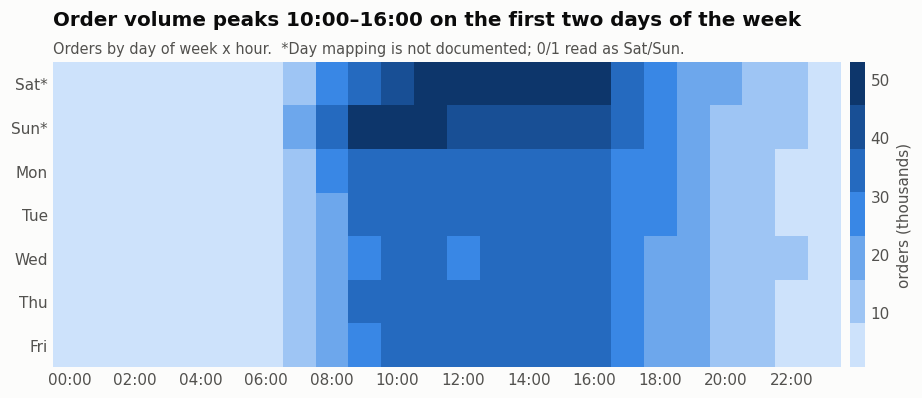

Share of orders placed 10:00-16:00: 57.4%
Busiest single slot: dow=1, hour=10


In [3]:
t = query(con, "02_shopping_time.sql")
grid = t.pivot(index="order_dow", columns="order_hour_of_day", values="orders")
day_labels = ["Sat*", "Sun*", "Mon", "Tue", "Wed", "Thu", "Fri"]

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid.values / 1000, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(style.BLUE_RAMP))
ax.set_yticks(range(7), day_labels)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("orders (thousands)")
cb.outline.set_visible(False)
ax.set_title("Order volume peaks 10:00–16:00 on the first two days of the week")
style.subtitle(ax, "Orders by day of week x hour.  *Day mapping is not documented; 0/1 read as Sat/Sun.")
style.save(fig, "01_order_heatmap")
plt.show()

peak = t.sort_values("orders", ascending=False).head(1)
share_10_16 = t.query("10 <= order_hour_of_day <= 16").orders.sum() / t.orders.sum()
print(f"Share of orders placed 10:00-16:00: {share_10_16:.1%}")
print(f"Busiest single slot: dow={peak.order_dow.item()}, hour={peak.order_hour_of_day.item()}")

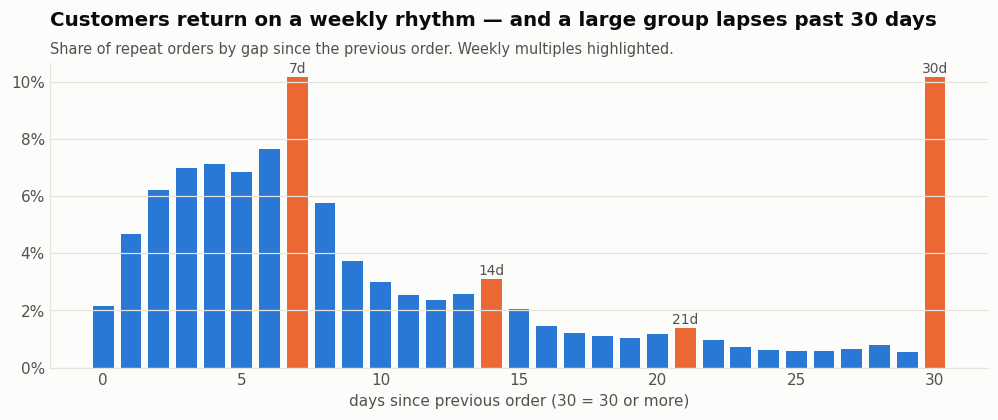

Repeat orders within 8 days: 57.7%  |  30+ days: 10.2%


In [4]:
r = query(con, "03_repurchase_cycle.sql")

fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [style.ORANGE if d in (7, 14, 21, 30) else style.BLUE for d in r.days_since_prior]
ax.bar(r.days_since_prior, r.pct, color=colors, width=0.75)
ax.set_xlabel("days since previous order (30 = 30 or more)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for d in (7, 14, 21, 30):
    v = r.loc[r.days_since_prior == d, "pct"].item()
    ax.annotate(f"{d}d", (d, v), xytext=(0, 3), textcoords="offset points", ha="center", color=style.TEXT_2, fontsize=9)
ax.set_title("Customers return on a weekly rhythm — and a large group lapses past 30 days")
style.subtitle(ax, "Share of repeat orders by gap since the previous order. Weekly multiples highlighted.")
style.save(fig, "02_repurchase_cycle")
plt.show()

weekly = r.query("days_since_prior <= 8").pct.sum()
lapsed = r.query("days_since_prior == 30").pct.item()
print(f"Repeat orders within 8 days: {weekly:.1f}%  |  30+ days: {lapsed:.1f}%")

## 3. Departments: traffic drivers vs. loyalty drivers

In [5]:
dept = query(con, "04_department_performance.sql")
dept

,department,lines,line_share_pct,order_penetration_pct,reorder_rate_pct
0,produce,9479291,29.23,74.9,65.0
1,dairy eggs,5414016,16.69,67.7,67.0
2,snacks,2887550,8.90,43.3,57.4
3,beverages,2690129,8.29,45.3,65.3
4,frozen,2236432,6.90,36.7,54.2
5,pantry,1875577,5.78,34.8,34.7
6,bakery,1176787,3.63,27.4,62.8
7,canned goods,1068058,3.29,21.2,45.7
8,deli,1051249,3.24,24.0,60.8
9,dry goods pasta,866627,2.67,18.6,46.1


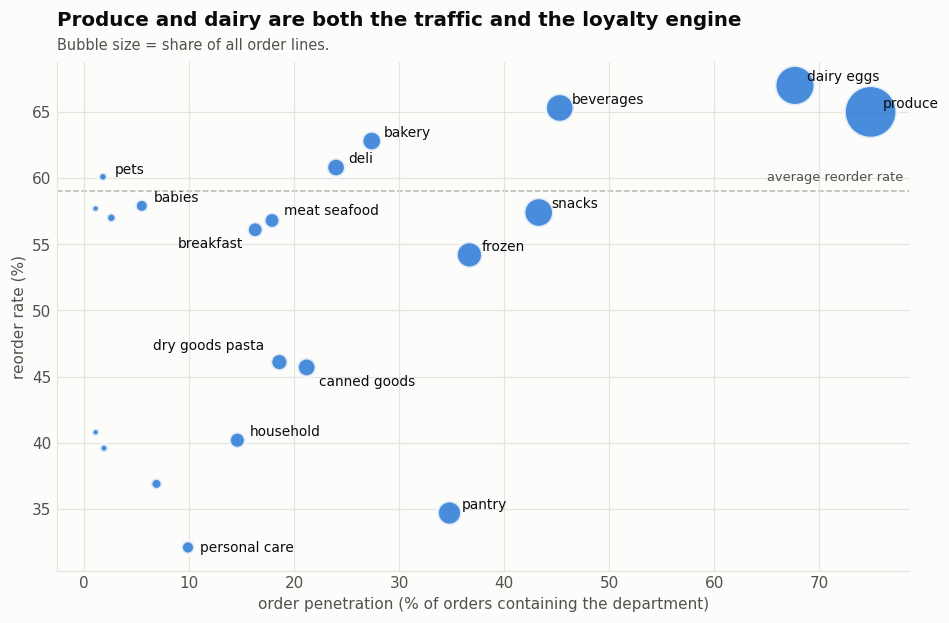

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, axis="both")
ax.scatter(dept.order_penetration_pct, dept.reorder_rate_pct, s=dept.line_share_pct * 40 + 20,
           color=style.BLUE, alpha=0.85, edgecolor=style.SURFACE, linewidth=2, zorder=3)
offsets = {"meat seafood": (8, 4), "breakfast": (-8, -12), "dry goods pasta": (-10, 8),
           "canned goods": (8, -12), "personal care": (8, -3), "babies": (8, 3), "pets": (8, 2)}
label = dept.query("order_penetration_pct > 14 or department in ('personal care', 'babies', 'pets')")
for _, row in label.iterrows():
    dx, dy = offsets.get(row.department, (8, 3))
    ax.annotate(row.department, (row.order_penetration_pct, row.reorder_rate_pct),
                xytext=(dx, dy), textcoords="offset points", fontsize=9, color=style.TEXT,
                ha="right" if dx < 0 else "left")
ax.axhline(kpis.reorder_rate_pct.item(), color=style.MUTED, lw=1, ls="--", zorder=1)
ax.text(78, kpis.reorder_rate_pct.item() + 0.8, "average reorder rate", color=style.TEXT_2, fontsize=8.5, ha="right")
ax.set_xlabel("order penetration (% of orders containing the department)")
ax.set_ylabel("reorder rate (%)")
ax.set_title("Produce and dairy are both the traffic and the loyalty engine")
style.subtitle(ax, "Bubble size = share of all order lines.")
style.save(fig, "03_department_matrix")
plt.show()

In [7]:
top = query(con, "05_top_products.sql")
top

,product_name,department,orders,reorder_rate_pct,avg_cart_position
0,Banana,produce,472565,84.4,4.9
1,Bag of Organic Bananas,produce,379450,83.3,5.1
2,Organic Strawberries,produce,264683,77.8,7.2
3,Organic Baby Spinach,produce,241921,77.3,7.4
4,Organic Hass Avocado,produce,213584,79.7,6.8
5,Organic Avocado,produce,176815,75.8,6.4
6,Large Lemon,produce,152657,69.6,7.9
7,Strawberries,produce,142951,69.8,7.1
8,Limes,produce,140627,68.1,8.6
9,Organic Whole Milk,dairy eggs,137905,83.0,5.4


### What goes into the cart first?
A *first-in-cart index* > 1 means the aisle is picked first more often than its overall share suggests —
these are **destination / mission** categories that bring the customer in.

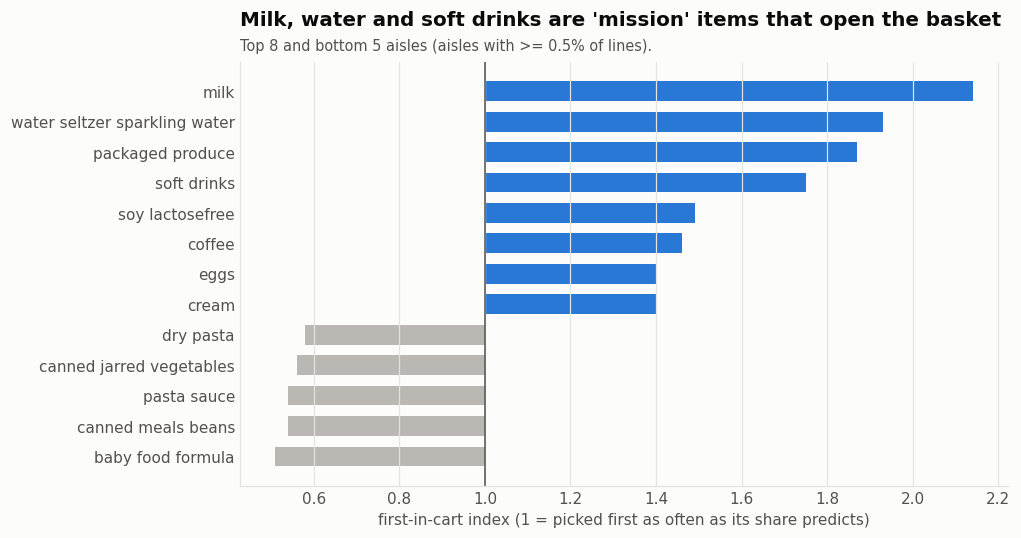

In [8]:
first = query(con, "06_first_in_cart.sql")
show = pd.concat([first.head(8), first.tail(5)])

fig, ax = plt.subplots(figsize=(9, 5))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
c = [style.BLUE if v >= 1 else style.MUTED for v in show.first_in_cart_index]
ax.barh(show.aisle[::-1], show.first_in_cart_index[::-1] - 1, left=1, color=c[::-1], height=0.65)
ax.axvline(1, color=style.TEXT_2, lw=1)
ax.set_xlabel("first-in-cart index (1 = picked first as often as its share predicts)")
ax.set_title("Milk, water and soft drinks are 'mission' items that open the basket")
style.subtitle(ax, "Top 8 and bottom 5 aisles (aisles with >= 0.5% of lines).")
style.save(fig, "04_first_in_cart")
plt.show()

## 4. Market basket analysis — product pairs (SQL)

Support, confidence and lift are computed **directly in SQL** with a self-join on the 1,000 most-ordered
products ([`07_product_pairs.sql`](../sql/07_product_pairs.sql)).

- **support** = share of all orders containing both products
- **confidence A→B** = P(B in basket | A in basket)
- **lift** = how much more often the pair co-occurs than if the two were independent (1 = no relationship)

In [9]:
pairs = query(con, "07_product_pairs.sql", top_n=1000, min_pair_orders=500)
pairs["same_aisle"] = pairs.aisle_a == pairs.aisle_b
top_cover = con.execute("""
    WITH t AS (SELECT product_id, COUNT(*) c FROM order_products GROUP BY 1 ORDER BY c DESC LIMIT 1000)
    SELECT SUM(c) / (SELECT COUNT(*) FROM order_products) FROM t""").fetchone()[0]
print(f"Top-1000 products cover {top_cover:.1%} of all order lines")
print(f"{len(pairs):,} pairs with >= 500 co-orders; {pairs.same_aisle.mean():.0%} of them are within the same aisle")
pairs.head(10)

Top-1000 products cover 54.0% of all order lines
27,275 pairs with >= 500 co-orders; 13% of them are within the same aisle


,product_a,product_b,aisle_a,aisle_b,pair_orders,support_pct,conf_a_to_b,conf_b_to_a,lift,same_aisle
0,Yotoddler Organic Pear Spinach Mango Yogurt,Organic Whole Milk Strawberry Beet Berry Yogurt Pouch,yogurt,yogurt,2823,0.088,0.461,0.449,235.91,True
1,Blueberry on the Bottom Nonfat Greek Yogurt,Strawberry on the Bottom Nonfat Greek Yogurt,yogurt,yogurt,2767,0.086,0.434,0.362,182.69,True
2,Organic Greek Nonfat Yogurt With Mixed Berries,Organic Nonfat Greek Yogurt With Peaches,yogurt,yogurt,2208,0.069,0.320,0.364,169.79,True
3,Cherry Pie Fruit & Nut Bar,Apple Pie Fruit & Nut Food Bar,energy granola bars,energy granola bars,2002,0.062,0.361,0.268,155.37,True
4,Strawberry Rhubarb Yogurt,Mixed Berries Whole Milk Icelandic Style Skyr Yogurt,yogurt,yogurt,2292,0.071,0.349,0.317,155.15,True
5,Blueberry on the Bottom Nonfat Greek Yogurt,Peach on the Bottom Nonfat Greek Yogurt,yogurt,yogurt,2371,0.074,0.372,0.305,153.65,True
6,Peach on the Bottom Nonfat Greek Yogurt,Strawberry on the Bottom Nonfat Greek Yogurt,yogurt,yogurt,2665,0.083,0.342,0.349,144.10,True
7,Broccoli & Apple Stage 2 Baby Food,Spinach Peas & Pear Stage 2 Baby Food,baby food formula,baby food formula,2339,0.073,0.342,0.291,136.88,True
8,Blueberry Muffin Bar,Apple Pie Fruit & Nut Food Bar,energy granola bars,energy granola bars,1826,0.057,0.318,0.244,136.54,True
9,Organic Greek Lowfat Yogurt With Strawberries,Organic Nonfat Greek Yogurt With Peaches,yogurt,yogurt,1619,0.050,0.257,0.267,135.94,True


The highest-lift pairs are almost all **flavour variants of the same product line** (e.g. Greek yogurt
flavours). That is a *variety-seeking* signal — useful for multi-buy offers ("any 4 for …") — but not for
cross-category placement. For cross-sell we look at pairs from **different aisles**.

In [10]:
same = pairs[pairs.same_aisle].nlargest(10, "lift")
cross = pairs[~pairs.same_aisle & (pairs.lift >= 3)].nlargest(15, "pair_orders")
cross[["product_a", "aisle_a", "product_b", "aisle_b", "pair_orders", "conf_a_to_b", "conf_b_to_a", "lift"]]

,product_a,aisle_a,product_b,aisle_b,pair_orders,conf_a_to_b,conf_b_to_a,lift
4506,Organic Strawberries,fresh fruits,Organic Raspberries,packaged vegetables fruits,33863,0.128,0.247,3.00
1026,Limes,fresh fruits,Organic Cilantro,fresh herbs,17565,0.125,0.253,5.78
3522,Organic Cucumber,fresh vegetables,Organic Hass Avocado,fresh fruits,17456,0.217,0.082,3.27
3384,Organic Garlic,fresh vegetables,Limes,fresh fruits,15946,0.145,0.113,3.32
3980,Large Lemon,fresh fruits,Cucumber Kirby,fresh vegetables,14457,0.095,0.149,3.13
4245,Organic Tomato Cluster,fresh vegetables,Organic Hass Avocado,fresh fruits,13061,0.203,0.061,3.06
924,Limes,fresh fruits,Bunched Cilantro,fresh herbs,12491,0.089,0.274,6.27
1468,Strawberries,fresh fruits,Raspberries,packaged produce,12106,0.085,0.210,4.72
1082,Organic Garlic,fresh vegetables,Organic Italian Parsley Bunch,fresh herbs,11539,0.105,0.190,5.57
957,Jalapeno Peppers,fresh vegetables,Limes,fresh fruits,11393,0.268,0.081,6.12


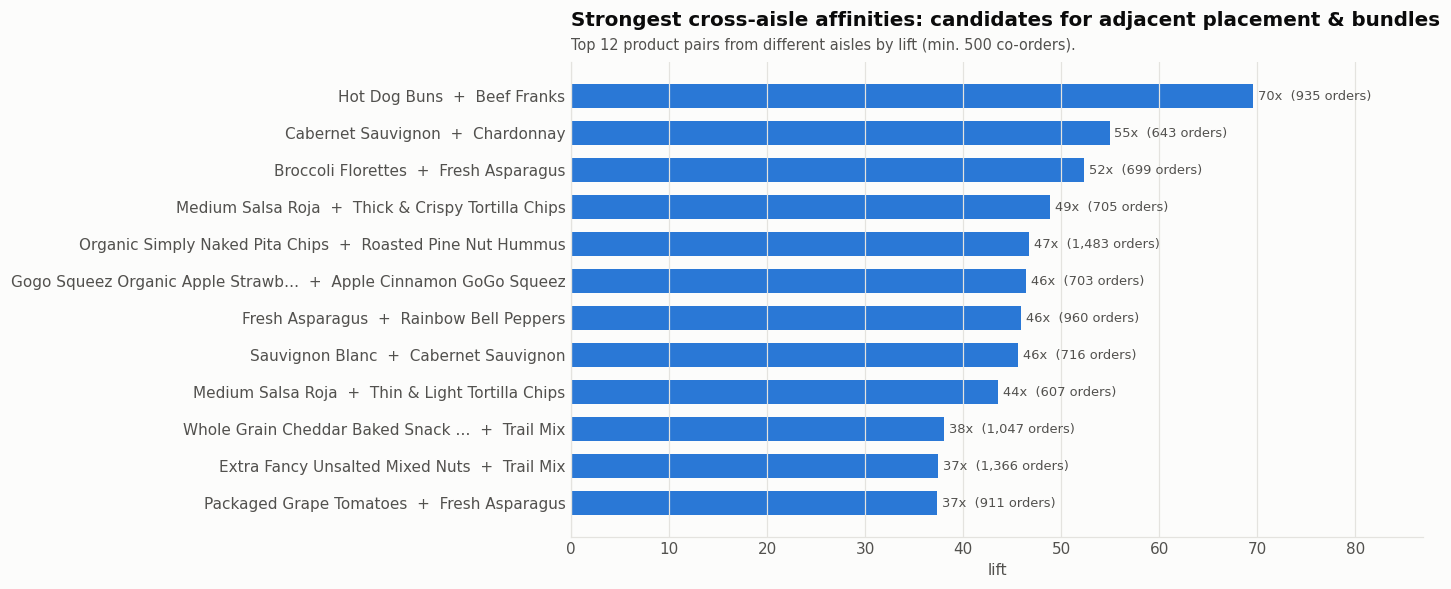

In [11]:
cr = pairs[~pairs.same_aisle].nlargest(12, "lift").copy()
short = lambda s: s if len(s) <= 34 else s[:32] + "…"
cr["label"] = cr.product_a.map(short) + "  +  " + cr.product_b.map(short)

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.barh(cr.label[::-1], cr.lift[::-1], color=style.BLUE, height=0.65)
for y, (v, n) in enumerate(zip(cr.lift[::-1], cr.pair_orders[::-1])):
    ax.text(v + 0.5, y, f"{v:.0f}x  ({n:,} orders)", va="center", fontsize=8.5, color=style.TEXT_2)
ax.set_xlabel("lift")
ax.set_xlim(0, cr.lift.max() * 1.25)
ax.set_title("Strongest cross-aisle affinities: candidates for adjacent placement & bundles")
style.subtitle(ax, "Top 12 product pairs from different aisles by lift (min. 500 co-orders).")
style.save(fig, "05_cross_aisle_pairs")
plt.show()

### Aisle-level association rules (Apriori)

Product pairs are granular; category managers think in aisles. We run Apriori (mlxtend) on a random sample of
300K baskets encoded at **aisle** level and keep rules with at least 3% support.

In [12]:
from mlxtend.frequent_patterns import apriori, association_rules

baskets = con.execute("""
    WITH s AS (SELECT order_id FROM orders USING SAMPLE 300000 ROWS (reservoir, 42))
    SELECT DISTINCT ol.order_id, ol.aisle
    FROM order_lines ol JOIN s USING (order_id)""").df()
onehot = pd.crosstab(baskets.order_id, baskets.aisle).astype(bool)
itemsets = apriori(onehot, min_support=0.03, use_colnames=True, max_len=3)
rules = association_rules(itemsets, metric="lift", min_threshold=1.2)
rules["antecedents"] = rules.antecedents.map(lambda s: " + ".join(sorted(s)))
rules["consequents"] = rules.consequents.map(lambda s: " + ".join(sorted(s)))
print(f"{onehot.shape[0]:,} baskets x {onehot.shape[1]} aisles -> {len(itemsets):,} frequent itemsets, {len(rules):,} rules")
(rules.sort_values("lift", ascending=False)
      [["antecedents", "consequents", "support", "confidence", "lift"]]
      .head(15).round(3))

300,000 baskets x 134 aisles -> 368 frequent itemsets, 946 rules


,antecedents,consequents,support,confidence,lift
824,fresh vegetables + packaged vegetables fruits,fresh herbs,0.047,0.200,2.136
825,fresh herbs,fresh vegetables + packaged vegetables fruits,0.047,0.501,2.136
50,chips pretzels,fresh dips tapenades,0.035,0.207,2.097
51,fresh dips tapenades,chips pretzels,0.035,0.352,2.097
562,fresh fruits + fresh vegetables,fresh herbs,0.061,0.193,2.069
563,fresh herbs,fresh fruits + fresh vegetables,0.061,0.657,2.069
702,fresh fruits + packaged cheese,lunch meat,0.033,0.212,2.049
707,lunch meat,fresh fruits + packaged cheese,0.033,0.316,2.049
822,fresh herbs + packaged vegetables fruits,fresh vegetables,0.047,0.894,2.014
827,fresh vegetables,fresh herbs + packaged vegetables fruits,0.047,0.106,2.014


## 5. Customer segments: frequency x basket size

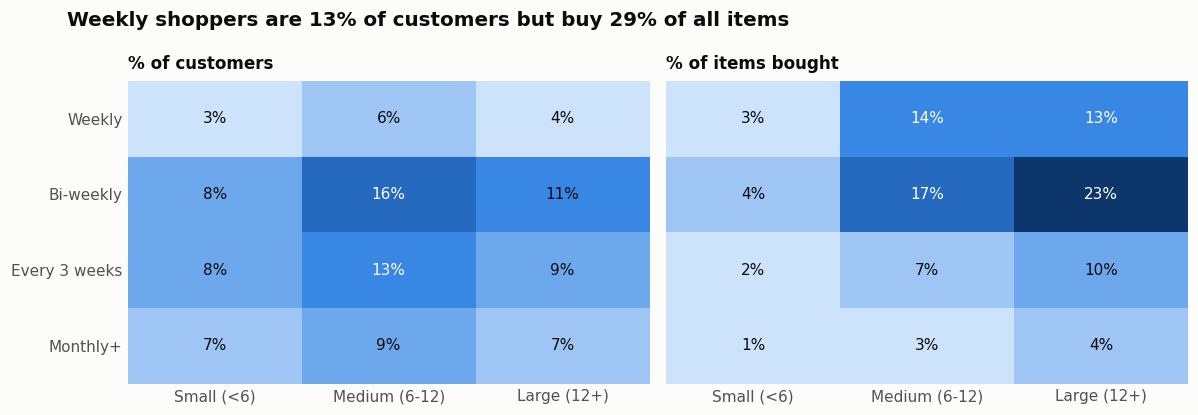

,customer_share,volume_share
frequency_segment,,
1. Weekly,0.132,0.294
2. Bi-weekly,0.346,0.437
3. Every 3 weeks,0.302,0.192
4. Monthly+,0.221,0.077


In [13]:
seg = query(con, "08_customer_segments.sql")
seg["customer_share"] = seg.customers / seg.customers.sum()
seg["volume_share"] = seg.total_items / seg.total_items.sum()
pc = seg.pivot(index="frequency_segment", columns="basket_segment", values="customer_share")[["Small (<6)", "Medium (6-12)", "Large (12+)"]]
pv = seg.pivot(index="frequency_segment", columns="basket_segment", values="volume_share")[pc.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
cmap = plt.matplotlib.colors.ListedColormap(style.BLUE_RAMP)
for ax, m, title in [(axes[0], pc, "% of customers"), (axes[1], pv, "% of items bought")]:
    ax.imshow(m.values, cmap=cmap, aspect="auto", vmin=0, vmax=0.25)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(range(3), m.columns)
    ax.set_yticks(range(4), [i.split(". ")[1] for i in m.index])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if v > 0.12 else style.TEXT)
    ax.set_title(title, fontsize=11, pad=8)
fig.suptitle("Weekly shoppers are 13% of customers but buy 29% of all items", x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
style.save(fig, "06_customer_segments")
plt.show()
seg.groupby("frequency_segment")[["customer_share", "volume_share"]].sum().round(3)

## 6. Key findings & recommendations

| # | Finding | Recommended action |
|---|---------|--------------------|
| 1 | **59% of all order lines are reorders**; the top products (bananas, milk, berries) are reordered 75–85% of the time. | Make "buy again" the default entry point of the app/online store; pre-fill baskets for repeat shoppers. |
| 2 | **57% of orders are placed 10:00–16:00**, with the heaviest load on the first two days of the week. | Weight delivery slots and picker staffing toward those windows; nudge flexible customers to off-peak slots with a small incentive. |
| 3 | **58% of repeat orders come within 8 days**, with a sharp spike at exactly 7 days — but **10% of repeat orders arrive after 30+ days**. | Trigger replenishment reminders on day 6–7; treat a 21+ day gap as an early churn signal for win-back offers. |
| 4 | Produce is in **75% of orders** with a 65% reorder rate; pantry reaches 35% of orders but only a **35% reorder rate**. | Use fresh produce quality as the loyalty lever; use pantry (stock-up, low-loyalty) categories for price promotions. |
| 5 | Milk is picked first **2.1x** more often than its share predicts; water and soft drinks ~1.8–1.9x. | These are *mission* categories: place them on the home screen / store entry, and attach recommendations to them. |
| 6 | The highest-lift product pairs are **flavour variants of the same line** (Greek yogurts, fruit bars, baby food). | Run "mix & match any N" multi-buy offers on these ranges instead of single-SKU discounts. |
| 7 | Clear **cross-aisle complements**: hot-dog buns + franks (lift 70), salsa + tortilla chips (49), pita chips + hummus (47); at volume, limes + cilantro (lift 6, 17.5K orders) and jalapeños → limes (27% confidence). | Secondary placements and "complete the meal" bundles (taco/guacamole kit, BBQ kit); cart-level recommendations in online channels. |
| 8 | Aisle-level rules confirm meal-occasion clusters: chips → fresh dips (lift 2.1), bread ↔ lunch meat (2.0), fresh herbs → fruit + vegetables (66% confidence). | Plan category adjacency around occasions (snacking, sandwich, cooking) rather than supplier categories. |
| 9 | **Weekly shoppers are 13% of customers but buy 29% of items**; bi-weekly large-basket customers are 11% of customers and 23% of items. | Prioritise these two segments in the loyalty programme (personalised offers, free delivery thresholds). |

**Limitations.** Instacart data has no prices, so findings are about volume and behaviour, not revenue or margin.
Days between orders are capped at 30, and the day-of-week mapping is not officially documented. Product-pair
mining is limited to the 1,000 most-ordered products (54% of all order lines).
